# Cristallina data with scipp: adapter and binned reciprocal-space maps

This notebook keeps the beamline stack for I/O and geometry:

* **sfdata** opens the files, matches pulse IDs and splits scans into steps,
* **jungfrau_utils** applies the Jungfrau gain, pedestal and geometry corrections,
* **cristallina.rsm** converts pixels to hkl,

and uses **scipp** from the reduced data onward:

1. one acquisition as pulse-aligned, labelled arrays, with photon-counting errors;
2. a scan reduced to per-step summed images with I0, then ROI intensities;
3. a reciprocal-space map built by **histogramming** instead of `griddata(method='nearest')`.

Parts 1 and 2 use the test run bundled with `cristallina_analysis_package`. That run has a single step, so part 3
uses a synthetic rocking scan generated with the beamline's own geometry code.

In [1]:
import warnings
from pathlib import Path
from unittest import mock

import numpy as np
import scipp as sc
import plopp as pp
import matplotlib.pyplot as plt
from sfdata import SFDataFiles, SFScanInfo

# import cristallina before patching: it replaces jungfrau_utils' file locators on import
import cristallina.rsm as crsm
from cristallina.utils import ROI

import cristallina_scipp as cs
from cristallina_scipp.rsm import pixel_hkl, histogram

warnings.filterwarnings("ignore", message="Skipping channel")  # empty motor channels in the test run

## Test data

The Jungfrau gain and pedestal files normally live under `/sf/jungfrau/config`. Offline, point jungfrau_utils at the
copies in the test data, as `cristallina`'s own tests do. On the Ra cluster, skip this cell.

In [2]:
DATA = Path("../../cristallina_analysis_package/tests/data").resolve()
RUN = DATA / "p20841/raw/run0205"

for target, path in [("locate_gain_file", DATA / "gains.h5"), ("locate_pedestal_file", DATA / "JF16T03V01.res.h5")]:
    mock.patch(f"jungfrau_utils.file_adapter.{target}", lambda p, path=path, **k: str(path)).start()

JF = "JF16T03V01"
GASMONITOR = "SARFE10-PBIG050-EVR0:CALCI"  # cristallina.channels.GASMONITOR
PHOTON_ENERGY = "SARUN:FELPHOTENE.VAL"     # keV, a PV: one value per acquisition

## 1. One acquisition as pulse-aligned arrays

`cs.step` drops pulses missing from any requested channel, so every entry shares one `pulse_id` coordinate.
Channels with different shapes go into a `DataGroup`.

In [3]:
with SFDataFiles(str(RUN / "data/acq0001.*.h5")) as data:
    dg = cs.step(data, [JF, GASMONITOR], units={JF: "keV", GASMONITOR: "uJ"})
    photon_energy = cs.channel(data[PHOTON_ENERGY], unit="keV").mean().data
dg

DataGroup(sizes={'pulse': 21, 'y': 1614, 'x': 1030}, keys=[
    JF16T03V01: DataArray({'pulse': 21, 'y': 1614, 'x': 1030}),
    SARFE10-PBIG050-EVR0:CALCI: DataArray({'pulse': 21}),
])

Convert the Jungfrau signal to photons and attach Poisson variances. From here on scipp carries the
uncertainties through every arithmetic operation.

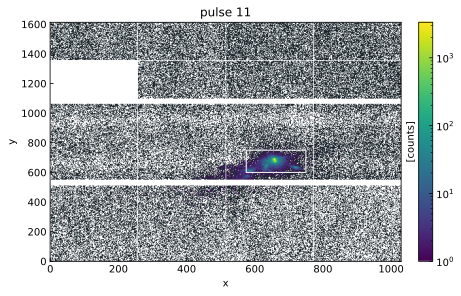

In [4]:
counts = dg[JF] / photon_energy
counts.unit = "counts"
counts.variances = np.clip(counts.values, 0, None)

fig = pp.plot(counts["pulse", 11], norm="log", vmin=1, title="pulse 11")
peak = ROI(left=575, right=750, bottom=600, top=750, name="peak")
fig.ax.add_patch(plt.Rectangle((peak.left, peak.bottom), peak.width, peak.height, fill=False, color="w"))
fig

Per-pulse ROI intensity normalised by the gas monitor. The error bars come from the photon variances.
Interactively, `pp.slicer(counts, keep=["x", "y"])` steps through the pulses.

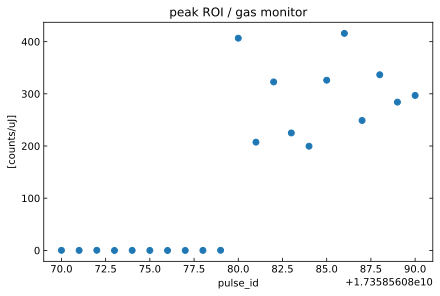

In [5]:
per_pulse = counts["y", peak.rows]["x", peak.cols].sum(["y", "x"]) / dg[GASMONITOR]
pp.plot(per_pulse, coords=["pulse_id"], title="peak ROI / gas monitor")

## 2. A scan: summed image per step, then ROIs

`cs.reduce_scan` reads the Jungfrau in batches, so memory stays bounded at any run length. It applies the
per-pulse cutoff as `cristallina.analysis.perform_image_stack_sum` does (the tests check that the two agree) and
keeps the I0 sum over the same pulses as a coordinate.

`scan.json` stores absolute `/sf/...` paths, so for the local copy we rewrite them.

In [6]:
scan = SFScanInfo(str(RUN / "meta/scan.json"))
scan.files = [[str(RUN / "data" / Path(f).name) for f in fs] for fs in scan.files]

stack = cs.reduce_scan(scan, JF, GASMONITOR, cutoff=4.0, photon_energy=photon_energy.value, i0_unit="uJ")
stack

<scipp.DataArray>
Dimensions: Sizes[step:1, y:1614, x:1030, ]
Coordinates:
* i0                        float64            [µJ]  (step)  [47428.6]
* n_pulses                    int64        <no unit>  (step)  [21]
* readback                  float64        <no unit>  (step)  [0]
* x                           int64        <no unit>  (x)  [0, 1, ..., 1028, 1029]
* y                           int64        <no unit>  (y)  [0, 1, ..., 1612, 1613]
Data:
                            float64         [counts]  (step, y, x)  [0, 0, ..., 0, 0]  [0, 0, ..., 0, 0]

In [7]:
background = ROI(left=800, right=975, bottom=600, top=750, name="background")
rois = cs.roi_intensities(stack, [peak, background])
signal = (rois["roi", 0] - rois["roi", 1]) / stack.coords["i0"]
signal

<scipp.DataArray>
Dimensions: Sizes[step:1, ]
Coordinates:
* i0                        float64            [µJ]  (step)  [47428.6]
* n_pulses                    int64        <no unit>  (step)  [21]
* readback                  float64        <no unit>  (step)  [0]
Data:
                            float64      [counts/uJ]  (step)  [156.56]  [0.00330799]

In a θ or energy scan, `signal` has one value per step with the readback as its coordinate, so the "intensity
vs. θ" tutorial becomes `pp.plot(signal, coords=["readback"])`. A warm/cold comparison becomes
`sc.concat([warm, cold], "temperature")`, with no parallel lists to keep in step.

## 3. Reciprocal-space map: histogram instead of nearest-neighbour interpolation

`cristallina.rsm.RSM` computes hkl for every ROI pixel at every step, concatenates them, and
`RSM_interpolate` fills a grid with `scipy.interpolate.griddata(method="nearest")`. This has two problems:

* every grid point receives the value of *one* nearby pixel, so no averaging takes place and there is no error estimate;
* grid points that no pixel came near are still filled, with a copy of some distant pixel.

Histogramming the counts and the monitor separately and dividing them gives counts per unit I0 in each voxel,
averaged over every pixel that landed there, with propagated errors. Voxels no pixel visited are `NaN`.

### Synthetic rocking scan

The geometry comes straight from `cristallina.rsm`. We use 1T-TaS$_2$ (the example in its docstring) at 9 keV,
with the detector at 2θ for (0 0 2), and rock the sample angle α through 10° in 41 steps. A 160×160 pixel ROI
around the detector centre is enough for the peak.

In [8]:
sample = crsm.Sample({"a": 0.336, "b": 0.336, "c": 0.5853, "alp": 90, "bet": 90, "gam": 120}, "1T-TaS2")
detector = crsm.Detector(R_m=0.15, px_size_um=75, center_pixel=(515, 807), detector_size_px=(1030, 1614))
energy = 9000.0  # eV

k = crsm.E_to_k(energy)  # 1/nm
two_theta = 2 * np.degrees(np.arcsin(2 * np.pi * 2 / sample.sample_dict["c"] / (2 * k)))
detector.move_angles(gamma=two_theta)

alpha = np.linspace(10, 20, 41)
ny = nx = 160
template = sc.DataArray(
    sc.zeros(dims=["step", "y", "x"], shape=[alpha.size, ny, nx], unit="counts"),
    coords={
        "readback": sc.array(dims=["step"], values=alpha, unit="deg"),
        "y": sc.arange("y", 807 - ny // 2, 807 + ny // 2, unit=None),
        "x": sc.arange("x", 515 - nx // 2, 515 + nx // 2, unit=None),
    },
)
geometry = pixel_hkl(template, sample, detector, energy)
{c: (round(geometry.coords[c].min().value, 3), round(geometry.coords[c].max().value, 3)) for c in "hkl"}

{'h': (np.float64(-0.097), np.float64(0.096)),
 'k': (np.float64(-0.166), np.float64(0.14)),
 'l': (np.float64(1.821), np.float64(2.165))}

Put an anisotropic Gaussian Bragg peak at (0 0 2) on a flat background, scale each step by a fluctuating I0,
and draw Poisson counts. The result has the same shape as `cs.reduce_scan` output: summed counts per pixel per
step, with variances and an `i0` coordinate.

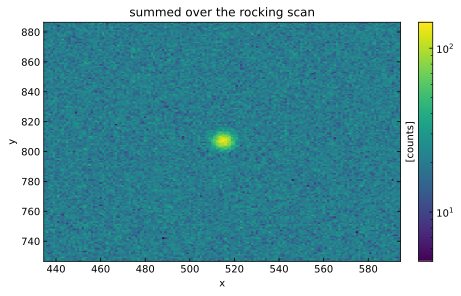

In [9]:
rng = np.random.default_rng(2026)
h, k_, l = (geometry.coords[c].values for c in "hkl")
sigma = {"h": 0.004, "k": 0.008, "l": 0.006}
true_rate = 0.5 + 20 * np.exp(-0.5 * ((h / sigma["h"]) ** 2 + (k_ / sigma["k"]) ** 2 + ((l - 2) / sigma["l"]) ** 2))
i0 = rng.uniform(0.5, 1.5, alpha.size)

synthetic = geometry.copy()
synthetic.values = rng.poisson(true_rate * i0[:, None, None]).astype(float)
synthetic.variances = synthetic.values.copy()
synthetic.coords["i0"] = sc.array(dims=["step"], values=i0)
pp.plot(synthetic.sum("step"), norm="log", title="summed over the rocking scan")

### Same grid, two methods

Grid spacing 0.004 r.l.u., as an `RSM_interpolate` call would use. The histogram edges sit half a step either side of
the same grid points, so both maps have the same voxel centres.

In [10]:
gs = 0.004
hbound, kbound = (-0.08, 0.08), (-0.12, 0.12)

# beamline method: per-step I0 normalisation, then nearest-neighbour griddata (as in cristallina.rsm.RSM)
normalised = (synthetic / synthetic.coords["i0"]).values
nearest = crsm.RSM_interpolate(h.ravel(), k_.ravel(), l.ravel(), normalised.ravel(), hbound, kbound, gs)

l_grid = np.arange(l.min(), l.max() + gs, gs)
h_grid = np.arange(hbound[0], hbound[1] + gs, gs)
k_grid = np.arange(kbound[0], kbound[1] + gs, gs)
nearest = sc.DataArray(
    sc.array(dims=["l", "h", "k"], values=nearest, unit="counts"),  # griddata over meshgrid(h, k, l), transposed
    coords={"h": sc.array(dims=["h"], values=h_grid), "k": sc.array(dims=["k"], values=k_grid),
            "l": sc.array(dims=["l"], values=l_grid)},
).transpose(["h", "k", "l"])

edges = lambda dim, grid: sc.array(dims=[dim], values=np.append(grid - gs / 2, grid[-1] + gs / 2))
binned = histogram(synthetic, h=edges("h", h_grid), k=edges("k", k_grid), l=edges("l", l_grid))
binned

<scipp.DataArray>
Dimensions: Sizes[h:41, k:61, l:88, ]
Coordinates:
* h                         float64  [dimensionless]  (h [bin-edge])  [-0.082, -0.078, ..., 0.078, 0.082]
* k                         float64  [dimensionless]  (k [bin-edge])  [-0.122, -0.118, ..., 0.118, 0.122]
* l                         float64  [dimensionless]  (l [bin-edge])  [1.81852, 1.82252, ..., 2.16652, 2.17052]
Data:
                            float64         [counts]  (h, k, l)  [-nan, -nan, ..., -nan, -nan]  [-nan, -nan, ..., -nan, -nan]

### k–l slice through the peak

The colour scale saturates at 10 so the background is visible. The left panel looks complete, but outside the
parallelogram the rocking scan swept, its values are copies of distant pixels. On the right, unvisited voxels stay
white, and the background inside is smoother because each voxel averages several pixels.

Text(646.5013888888888, 0.5, '')

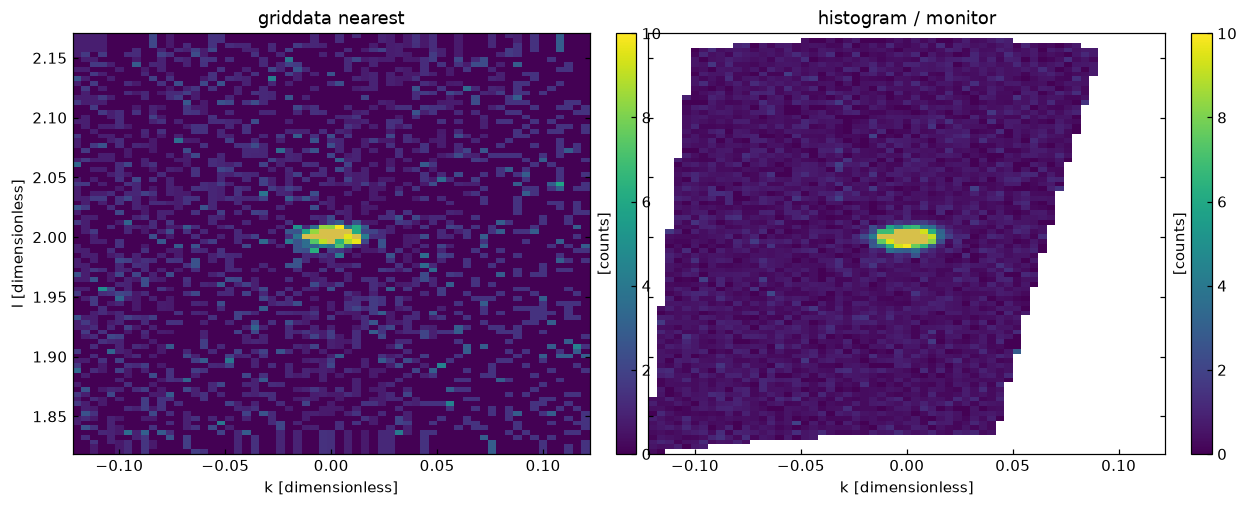

In [11]:
h0 = int(np.argmin(np.abs(h_grid)))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, layout="constrained")
for ax, (name, m) in zip(axs, [("griddata nearest", nearest), ("histogram / monitor", binned)]):
    pp.plot(m["h", h0].transpose(["l", "k"]), ax=ax, vmin=0, vmax=10, title=name)
axs[1].set_ylabel("")

In [12]:
visited = np.isfinite(binned.values)
print(f"voxels in grid: {binned.data.size}, visited by at least one pixel: {visited.sum()} ({visited.mean():.0%})")
print(f"griddata 'nearest' returned values for all {np.isfinite(nearest.values).sum()} of them")

voxels in grid: 220088, visited by at least one pixel: 147136 (67%)
griddata 'nearest' returned values for all 220088 of them


### Cut along k through (0 0 2)

Each nearest-neighbour value is one pixel's Poisson draw. Each histogram voxel averages every pixel in it and carries
a propagated error. The dashed line is the model the counts were drawn from.

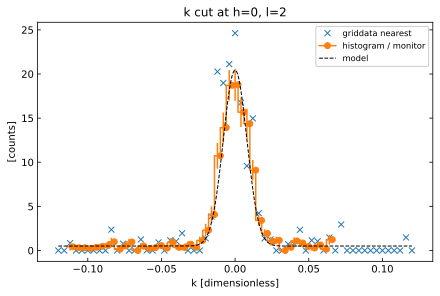

In [13]:
l0 = int(np.argmin(np.abs(l_grid - 2)))
cut = {"griddata nearest": nearest["h", h0]["l", l0], "histogram / monitor": binned["h", h0]["l", l0]}
fig = pp.plot(cut, linestyle={"griddata nearest": "none"}, marker={"griddata nearest": "x", "histogram / monitor": "o"},
              title="k cut at h=0, l=2")
kk = np.linspace(*kbound, 400)
fig.ax.plot(kk, 0.5 + 20 * np.exp(-0.5 * ((h_grid[h0] / sigma["h"]) ** 2 + (kk / sigma["k"]) ** 2 + ((l_grid[l0] - 2) / sigma["l"]) ** 2)),
            "k--", lw=1, label="model")
fig.ax.legend()
fig

The binned map is an ordinary scipp DataArray, so it can be sliced, rebinned (`binned.hist(...)`, or coarser
edges for weak features), integrated over a peak with its errors, or browsed with `pp.slicer(binned, keep=["k", "l"])`.

## At the beamtime

The only change is where the stack comes from. The angles and channels follow `cristallina.rsm.RSM`:

```python
import cristallina as cr
from cristallina import channels

scan = cr.utils.scan_info(run_number, pgroup="p2xxxx")
with scan[0] as first:
    energy_eV = np.asarray(first["SAROP31-ODCC110:MOT_ENY.RBV"].data).ravel()[0]
    two_theta = np.mean(first["SARES31-GPS:ROT2THETA-BS"].data)

stack = cs.reduce_scan(scan, channels.JF, channels.GASMONITOR, roi=roi, cutoff=7.6,
                       photon_energy=energy_eV / 1000, readback_unit="deg")
detector.move_angles(gamma=two_theta)
rsm = histogram(pixel_hkl(stack, sample, detector, energy_eV, offset=offset), h=60, k=60, l=80)
```

`cristallina.analysis.calculate_JF_stacks` normalises by the integrated I0 Jungfrau (`channels.JF_I0`) rather than the
gas monitor. To do the same, pass that channel as `i0`. It is summed over all pixels, which reads its full images, so
this only makes sense for a small I0 detector.